# 2. Thuật toán di truyền (GA) tối ưu tham số FSRS

GA (Holland / Goldberg) tìm **một bộ 17 tham số FSRS** dự đoán nhớ / quên tốt nhất trên lịch sử ôn của mọi người học
(`BE/apps/algorithms/ga.py`):

| Thành phần | Cài đặt |
|---|---|
| Nhiễm sắc thể | 17 gen thực trong miền giới hạn `fsrs.BOUNDS` |
| Độ thích nghi | − log-loss của dự đoán trên tập train |
| Chọn lọc | Tournament, kích thước 3 |
| Lai ghép | BLX-α (α = 0,3), xác suất 0,9 |
| Đột biến | Gauss, σ = 10 % miền giá trị, xác suất 0,15 mỗi gen |
| Tinh hoa | Giữ 2 cá thể tốt nhất |

Thẻ được chia 80 % train / 20 % test; bộ tham số chỉ được áp dụng nếu **tốt hơn trên tập test** (dữ liệu GA chưa thấy).

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


## 2.1 Tham số chạy (chỉnh được)

In [2]:
POPULATION = 24     # số cá thể mỗi thế hệ
GENERATIONS = 25    # số thế hệ
SEED = 0
APPLY = True        # ghi bộ tham số mới vào cấu hình hệ thống nếu tốt hơn trên tập test

In [3]:
from apps.algorithms import evaluation, fsrs, ga
from apps.algorithms.models import AlgorithmConfig, ExperimentRun

hist = evaluation.histories()
train, test = evaluation.split(hist)
print(f"train {len(train):,} thẻ – test {len(test):,} thẻ")
print("log-loss tham số mặc định trên train:", round(-ga.fitness(fsrs.DEFAULT_W, train), 4))

train 2,765 thẻ – test 691 thẻ
log-loss tham số mặc định trên train: 0.6961


## 2.2 Huấn luyện

In [4]:
t0 = time.time()
out = ga.run(train, POPULATION, GENERATIONS, seed=SEED)
duration = time.time() - t0
print(f"Xong sau {duration:.0f}s")

  thế hệ 0: log-loss tốt nhất 0.5562 (0s)


  thế hệ 5: log-loss tốt nhất 0.5306 (2s)


  thế hệ 10: log-loss tốt nhất 0.5270 (5s)


  thế hệ 15: log-loss tốt nhất 0.5260 (7s)


  thế hệ 20: log-loss tốt nhất 0.5260 (9s)


Xong sau 11s


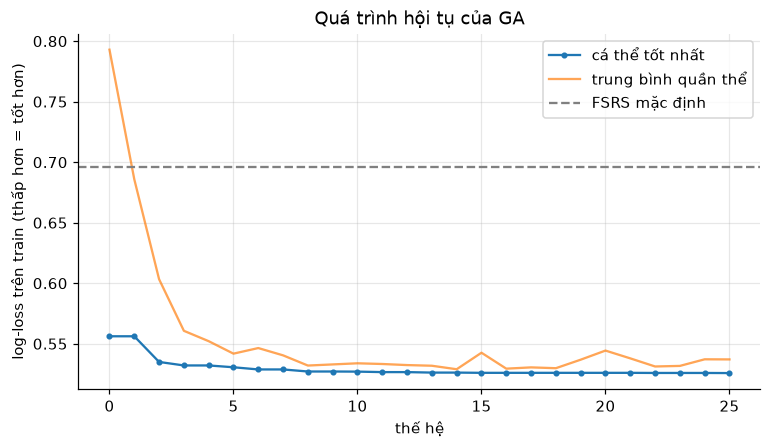

In [5]:
gen = [h["generation"] for h in out["history"]]
fig, ax = plt.subplots()
ax.plot(gen, [h["best"] for h in out["history"]], marker="o", ms=3, label="cá thể tốt nhất")
ax.plot(gen, [h["mean"] for h in out["history"]], alpha=0.7, label="trung bình quần thể")
ax.axhline(-ga.fitness(fsrs.DEFAULT_W, train), ls="--", c="gray", label="FSRS mặc định")
ax.set_xlabel("thế hệ")
ax.set_ylabel("log-loss trên train (thấp hơn = tốt hơn)")
ax.set_title("Quá trình hội tụ của GA")
ax.legend()
save(fig, "02_ga_hoi_tu")
plt.show()

## 2.3 Đánh giá trên tập test

mô hình        n     log_loss  rmse    auc     accuracy
-------------  ----  --------  ------  ------  --------
FSRS mặc định  1635  0.7086    0.4873  0.6909  0.6758  
FSRS + GA      1635  0.5210    0.4147  0.7713  0.7688  
SM-2           1635  0.6319    0.4652  0.6357  0.6881  


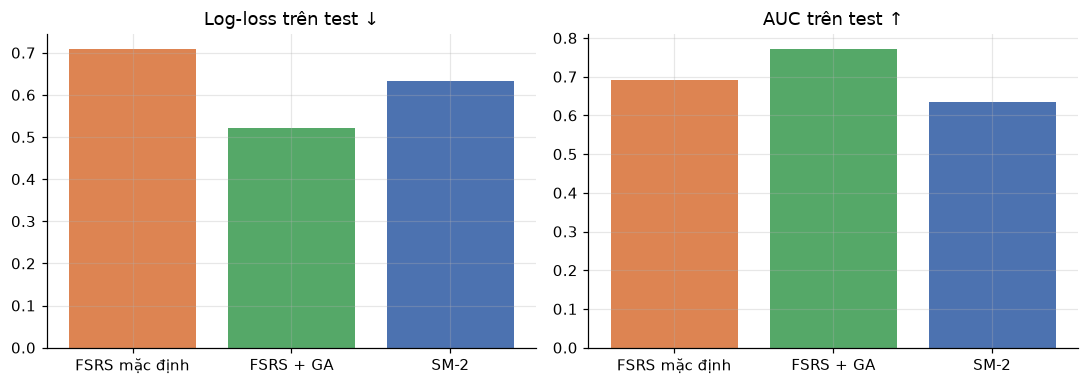

In [6]:
res_test = {"FSRS mặc định": evaluation.metrics([x for h in test for x in evaluation.predict_fsrs(h)]),
            "FSRS + GA": evaluation.metrics([x for h in test for x in evaluation.predict_fsrs(h, out["weights"])]),
            "SM-2": evaluation.metrics([x for h in test for x in evaluation.predict_sm2(h)])}
table([{"mô hình": k, **{m: v[m] for m in ("n", "log_loss", "rmse", "auc", "accuracy")}} for k, v in res_test.items()])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, m, title in zip(ax, ("log_loss", "auc"), ("Log-loss trên test ↓", "AUC trên test ↑")):
    a.bar(list(res_test), [v[m] for v in res_test.values()], color=["#dd8452", "#55a868", "#4c72b0"])
    a.set_title(title)
fig.tight_layout()
save(fig, "02_ga_test")
plt.show()

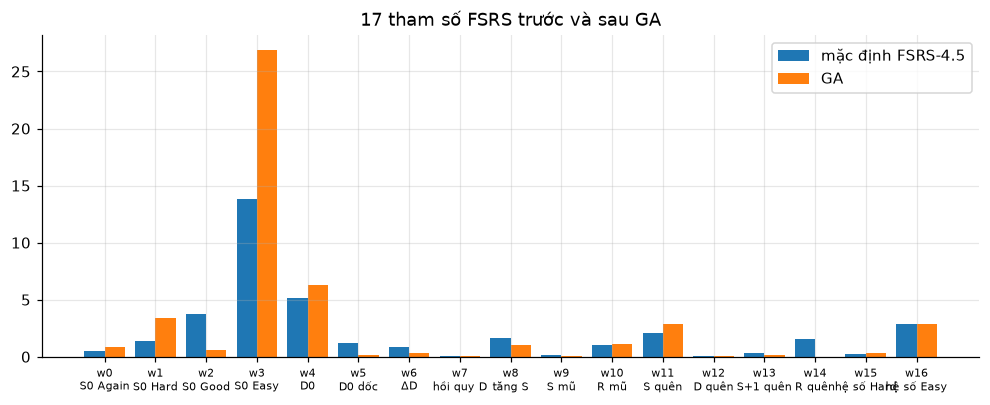

w_GA = [0.8171, 3.4344, 0.579, 26.8639, 6.324, 0.139, 0.3071, 0.1009, 0.9948, 0.0696, 1.0895, 2.847, 0.0907, 0.1491, 0.0115, 0.3359, 2.8915]


In [7]:
names = ["S0 Again", "S0 Hard", "S0 Good", "S0 Easy", "D0", "D0 dốc", "ΔD", "hồi quy D", "tăng S", "S mũ",
         "R mũ", "S quên", "D quên", "S+1 quên", "R quên", "hệ số Hard", "hệ số Easy"]
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(17)
ax.bar(x - 0.2, fsrs.DEFAULT_W, 0.4, label="mặc định FSRS-4.5")
ax.bar(x + 0.2, out["weights"], 0.4, label="GA")
ax.set_xticks(x, [f"w{i}\n{n}" for i, n in enumerate(names)], fontsize=7)
ax.set_title("17 tham số FSRS trước và sau GA")
ax.legend()
save(fig, "02_ga_tham_so")
plt.show()
print("w_GA =", out["weights"])

## 2.4 Lưu kết quả (và áp dụng nếu tốt hơn trên test)

In [8]:
improved = res_test["FSRS + GA"]["log_loss"] < res_test["FSRS mặc định"]["log_loss"]
applied = bool(APPLY and improved)
if applied:
    cfg = AlgorithmConfig.get()
    cfg.fsrs_weights = out["weights"]
    cfg.save(update_fields=["fsrs_weights", "updated_at"])
results = {**out, "train_cards": len(train), "test_cards": len(test), "applied": applied,
           "test": {"fsrs_default": res_test["FSRS mặc định"], "fsrs_ga": res_test["FSRS + GA"], "sm2": res_test["SM-2"]}}
run = ExperimentRun.objects.create(kind="ga", results=results, duration_s=round(duration, 2))
print("Đã lưu ExperimentRun", run.id, "| áp dụng vào hệ thống:", applied)

Đã lưu ExperimentRun 33 | áp dụng vào hệ thống: True
